## Pollen Detection in Honey Bee Images

Given *images of honeybees*, let's try to detect **pollen** in a given image.

We will use a TensorFlow/Keras convolutional neural network to make our predictions.

Data source: https://www.kaggle.com/datasets/ivanfel/honey-bee-pollen

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report

I0000 00:00:1793205259.661138    6085 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793205260.044037    6085 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793205262.189729    6085 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
data = pd.read_csv('archive/PollenDataset/pollen_data.csv', usecols=['filename', 'pollen_carrying'])
data

,filename,pollen_carrying
0,P10057-125r.jpg,1
1,P57380-120r.jpg,1
2,NP63671-221r.jpg,0
3,NP53776-47r.jpg,0
4,NP13382-201r.jpg,0
...,...,...
709,NP64239-233r.jpg,0
710,NP10304-132r.jpg,0
711,NP28671-238r.jpg,0
712,P14163-218r.jpg,1


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   filename         714 non-null    object
 1   pollen_carrying  714 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 11.3+ KB


### Preprocessing

In [4]:
df = data.copy()

In [5]:
'archive/PollenDataset/images' / Path('NP220-1r.jpg')

PosixPath('archive/PollenDataset/images/NP220-1r.jpg')

In [6]:
# Change filenames into filepaths
image_path = 'archive/pollendataset/PollenDataset/images'
df['filename'] = df['filename'].apply(lambda x: image_path / Path(x)).astype(str)

In [7]:
# Create text labels for the images 
df['pollen_carrying'] = df['pollen_carrying'].replace({0: 'NO POLLEN', 1: 'POLLEN'})

In [8]:
df

,filename,pollen_carrying
0,archive/pollendataset/PollenDataset/images/P10...,POLLEN
1,archive/pollendataset/PollenDataset/images/P57...,POLLEN
2,archive/pollendataset/PollenDataset/images/NP6...,NO POLLEN
3,archive/pollendataset/PollenDataset/images/NP5...,NO POLLEN
4,archive/pollendataset/PollenDataset/images/NP1...,NO POLLEN
...,...,...
709,archive/pollendataset/PollenDataset/images/NP6...,NO POLLEN
710,archive/pollendataset/PollenDataset/images/NP1...,NO POLLEN
711,archive/pollendataset/PollenDataset/images/NP2...,NO POLLEN
712,archive/pollendataset/PollenDataset/images/P14...,POLLEN


In [9]:
# Train-test split
train_df, test_df = train_test_split(df, train_size=0.7, shuffle=True, random_state=1)

In [10]:
train_df

,filename,pollen_carrying
507,archive/pollendataset/PollenDataset/images/P63...,POLLEN
346,archive/pollendataset/PollenDataset/images/NP1...,NO POLLEN
160,archive/pollendataset/PollenDataset/images/P27...,POLLEN
463,archive/pollendataset/PollenDataset/images/NP1...,NO POLLEN
432,archive/pollendataset/PollenDataset/images/P61...,POLLEN
...,...,...
144,archive/pollendataset/PollenDataset/images/P58...,POLLEN
645,archive/pollendataset/PollenDataset/images/NP5...,NO POLLEN
72,archive/pollendataset/PollenDataset/images/P14...,POLLEN
235,archive/pollendataset/PollenDataset/images/NP1...,NO POLLEN


### Creating Generators

In [11]:
train_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale = 1. / 255,
    validation_split = 0.2
)

test_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale = 1. / 255
)

In [12]:
train_images = train_generator.flow_from_dataframe(
    dataframe = train_df,
    x_col = 'filename',
    y_col = 'pollen_carrying',
    target_size = (224, 224),
    color_mode = 'rgb',
    class_mode = 'binary',
    batch_size = 32,
    shuffle = True,
    seed = 42,
    subset = 'training'
)

val_images = train_generator.flow_from_dataframe(
    dataframe = train_df,
    x_col = 'filename',
    y_col = 'pollen_carrying',
    target_size = (224, 224),
    color_mode = 'rgb',
    class_mode = 'binary',
    batch_size = 32,
    shuffle = True,
    seed = 42,
    subset = 'validation'
)

test_images = test_generator.flow_from_dataframe(
    dataframe = test_df,
    x_col = 'filename',
    y_col = 'pollen_carrying',
    target_size = (224, 224),
    color_mode = 'rgb',
    class_mode = 'binary',
    batch_size = 32
)

Found 400 validated image filenames belonging to 2 classes.
Found 99 validated image filenames belonging to 2 classes.
Found 215 validated image filenames belonging to 2 classes.


### Training

In [13]:
inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.layers.Conv2D(filters = 16, kernel_size=(3,3), activation='relu')(inputs)
x = tf.keras.layers.MaxPool2D()(x)
x = tf.keras.layers.Conv2D(filters = 32, kernel_size=(3,3), activation='relu')(x)
x = tf.keras.layers.MaxPool2D()(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = [
        'accuracy'
    ]
)

history = model.fit(
    train_images,
    validation_data = val_images,
    epochs = 100,
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor = 'val_loss',
            patience = 5,
            restore_best_weights = True
        )
    ]
)

E0000 00:00:1793205263.012538    6085 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/100


I0000 00:00:1793205263.287055    6085 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1793205264.914846    6119 cpu_allocator_impl.cc:82] Allocation of 100933632 exceeds 10% of free system memory.
W0000 00:00:1793205265.135950    6119 cpu_allocator_impl.cc:82] Allocation of 25233408 exceeds 10% of free system memory.
W0000 00:00:1793205265.218730    6119 cpu_allocator_impl.cc:82] Allocation of 48664576 exceeds 10% of free system memory.
W0000 00:00:1793205265.324447    6119 cpu_allocator_impl.cc:82] Allocation of 23887872 exceeds 10% of free system memory.
W0000 00:00:1793205265.324819    6119 cpu_allocator_impl.cc:82] Allocation of 48664576 exceeds 10% of free system memory.


13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 836ms/step - accuracy: 0.5275 - loss: 0.6930 - val_accuracy: 0.4545 - val_loss: 0.6947
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 873ms/step - accuracy: 0.5275 - loss: 0.6907 - val_accuracy: 0.4545 - val_loss: 0.6964
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 923ms/step - accuracy: 0.5250 - loss: 0.6906 - val_accuracy: 0.4545 - val_loss: 0.6960
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 835ms/step - accuracy: 0.5275 - loss: 0.6946 - val_accuracy: 0.4545 - val_loss: 0.6980
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 20s 828ms/step - accuracy: 0.5275 - loss: 0.6900 - val_accuracy: 0.4545 - val_loss: 0.6949
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 828ms/step - accuracy: 0.5275 - loss: 0.6892 - val_accuracy: 0.4545 - val_loss: 0.6907
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 830ms/step - accuracy: 0.5275 - loss: 0.6848 - val_accuracy: 0.4545 - val_loss: 0.6892
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 775ms/step - accuracy: 0.5275 - loss: 0.6798 - val_accuracy

### Results

In [14]:
results = model.evaluate(test_images)

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 288ms/step - accuracy: 0.8605 - loss: 0.3413


In [15]:
print("Accuracy: {:.2f}%".format(results[1] * 100))

Accuracy: 86.05%


In [16]:
predictions = model.predict(test_images)

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 319ms/step


In [17]:
predictions = (np.squeeze(predictions) >= 0.5).astype(int)
predictions

array([1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1])

In [18]:
test_images.class_indices

{'NO POLLEN': 0, 'POLLEN': 1}

In [19]:
np.array(test_images.labels)

array([0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1])

In [20]:
from sklearn.metrics import accuracy_score

In [21]:
accuracy_score(test_images.labels, predictions)

0.5162790697674419

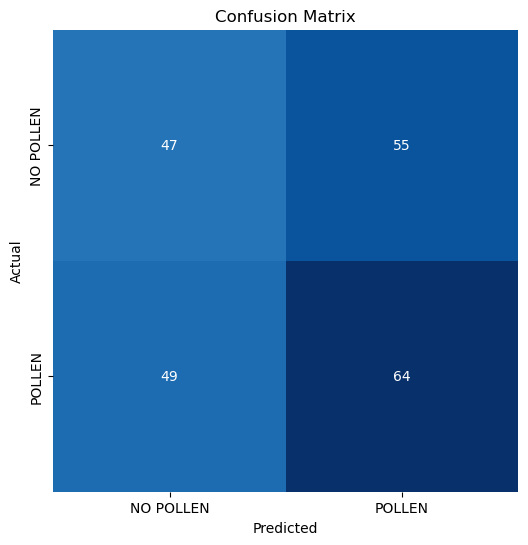

In [22]:
cm = confusion_matrix(test_images.labels, predictions, labels=[0,1])
clr = classification_report(test_images.labels, predictions, labels=[0, 1], target_names = ['NO POLLEN', 'POLLEN'])

plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cmap='Blues', cbar=False)
plt.xticks(ticks=[0.5, 1.5], labels=['NO POLLEN', 'POLLEN'])
plt.yticks(ticks=[0.5, 1.5], labels=['NO POLLEN', 'POLLEN'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()
plt.close()

In [23]:
print("Classification Report:\n-----------------------------------------\n", clr)

Classification Report:
-----------------------------------------
               precision    recall  f1-score   support

   NO POLLEN       0.49      0.46      0.47       102
      POLLEN       0.54      0.57      0.55       113

    accuracy                           0.52       215
   macro avg       0.51      0.51      0.51       215
weighted avg       0.51      0.52      0.52       215



In [26]:
test_images[0][0][5]

array([[[0.19607845, 0.49411768, 0.63529414],
        [0.19215688, 0.4901961 , 0.6313726 ],
        [0.19215688, 0.4901961 , 0.6313726 ],
        ...,
        [0.14117648, 0.37254903, 0.4901961 ],
        [0.14117648, 0.37254903, 0.4901961 ],
        [0.14117648, 0.37254903, 0.4901961 ]],

       [[0.18823531, 0.48627454, 0.627451  ],
        [0.18823531, 0.48627454, 0.627451  ],
        [0.18431373, 0.48235297, 0.62352943],
        ...,
        [0.13333334, 0.3647059 , 0.48235297],
        [0.12941177, 0.36078432, 0.4784314 ],
        [0.12941177, 0.36078432, 0.4784314 ]],

       [[0.18823531, 0.48627454, 0.627451  ],
        [0.18431373, 0.48235297, 0.62352943],
        [0.18431373, 0.48235297, 0.62352943],
        ...,
        [0.13333334, 0.3647059 , 0.48235297],
        [0.13333334, 0.3647059 , 0.48235297],
        [0.13333334, 0.3647059 , 0.48235297]],

       ...,

       [[0.21568629, 0.48235297, 0.627451  ],
        [0.21960786, 0.48627454, 0.6313726 ],
        [0.22352943, 0

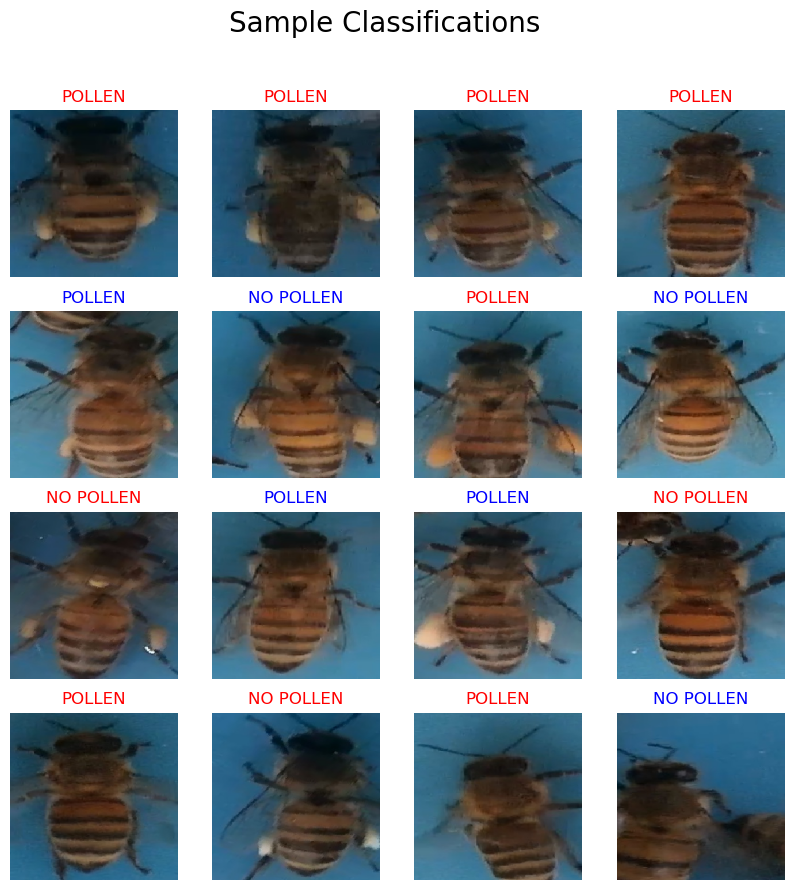

In [32]:
plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(test_images[0][0][i])
    plt.title(
        'NO POLLEN' if predictions[i] == 0 else 'POLLEN',
        color = 'blue' if predictions[i] == test_images.labels[i] else 'red'
    )
    plt.axis('off')

plt.suptitle('Sample Classifications', size=20)
plt.show()